# Day 6 — EDA, step by step

### A guided walkthrough you can actually learn from

**Week 2 · Day 6 · Sat Oct 25** · `guide.ipynb`

---

## What is EDA?

**Exploratory Data Analysis (EDA)** is what you do *before* modelling: you look at the data until
you understand its shape, its problems and its story. The output is not a model — it is a small set
of **decisions** and **insights** that the rest of the project depends on.

A useful definition for an interview:

> "EDA is the process of checking a dataset's structure, quality and relationships so that modelling
> decisions are based on evidence rather than assumptions."

### The 7-step workflow used in this notebook

| # | Step | Question it answers |
|---|---|---|
| 1 | Shape & types | How much data, and what is each column? |
| 2 | Missing values | What is absent, and does the absence mean something? |
| 3 | Duplicates & keys | Is each row a unique thing? |
| 4 | Target balance | How common is the outcome? What does "good" mean? |
| 5 | Distributions | What do the numbers look like (centre, spread, skew)? |
| 6 | Target vs features | Which groups churn more? |
| 7 | Correlations & leakage | What moves together — and what is secretly the answer? |

### How to use this notebook

* Run the cells in order (`Shift + Enter`). Every output is already saved, so you can also just read.
* After each output, **write one sentence in your own words** before moving on. Reading teaches
  syntax; writing conclusions teaches the job.
* Blocks marked **Why this matters** are the interview answers.
* Blocks marked **Trap** are mistakes that silently ruin analyses.

**Dataset:** `telecom_churn.csv` — 3,500 customers × 23 columns, generated by `generate_data.py`
(seed 42). It is synthetic but contains realistic problems **on purpose**: missing values, a derived
column, and four leakage columns.

## 0. Setup

Two cells: imports/options, then load the data. The load cell looks in `data/` first and falls back
to the Day 5 folder, so the notebook works from either location.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# --- display options: make wide tables readable ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)

print("pandas ", pd.__version__)
print("numpy  ", np.__version__)

pandas  3.0.6
numpy   2.5.4


In [2]:
candidates = [Path("data/telecom_churn.csv"), Path("../d5/telecom_churn.csv")]
DATA = next((p for p in candidates if p.exists()), None)
assert DATA is not None, (
    "Dataset not found. Run `python generate_data.py` in this folder first."
)

raw = pd.read_csv(DATA)
print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns from {DATA}")

Loaded 3,500 rows x 23 columns from data\telecom_churn.csv


## 1. Shape, types and a first look

`shape` tells you the size. `head()` shows the first rows. `info()` is the single most useful
command in pandas: it lists every column, its type and how many non-missing values it has.

In [3]:
print("Rows, columns:", raw.shape)
print("\nFirst 3 rows:")
display(raw.head(3))

Rows, columns: (3500, 23)

First 3 rows:


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,tech_support,streaming_tv,contract,paperless_billing,payment_method,monthly_charges,total_charges,customer_service_calls,satisfaction_score,cancellation_request,last_interaction_status,churn_risk_post_exit_code,churn
0,CUST-10000,Male,0,Yes,Yes,6,Yes,Yes,Fiber optic,Yes,No,No,Two year,No,Credit card (automatic),93.88,590.03,6.0,1,Recorded,Retention Declined,999,1
1,CUST-10001,Female,0,Yes,Yes,7,Yes,No,DSL,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.78,578.74,3.0,2,Recorded,Account Closed,999,1
2,CUST-10002,Female,1,No,No,60,Yes,No,Fiber optic,No,No,No,Month-to-month,No,Mailed check,74.06,4435.36,4.0,2,Recorded,Account Closed,999,1


In [4]:
# info() prints to the console rather than returning a table
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                3500 non-null   str    
 1   gender                     3500 non-null   str    
 2   senior_citizen             3500 non-null   int64  
 3   partner                    3500 non-null   str    
 4   dependents                 3500 non-null   str    
 5   tenure_months              3500 non-null   int64  
 6   phone_service              3500 non-null   str    
 7   multiple_lines             3500 non-null   str    
 8   internet_service           3500 non-null   str    
 9   online_security            3500 non-null   str    
 10  tech_support               3440 non-null   str    
 11  streaming_tv               3500 non-null   str    
 12  contract                   3500 non-null   str    
 13  paperless_billing          3500 non-null   str    
 14  pay

**How to read `info()`**

* `RangeIndex: 3500 entries` → 3,500 rows.
* `float64` / `int64` → numbers; `str` → text.
* `Non-Null Count` → how many values exist. `total_charges 3455` means **45 are missing**.
* `customer_service_calls` is `float64` even though calls are whole numbers — because of the 35
  missing values. That is a useful clue, not a bug.

**Why this matters.** Types decide what you are allowed to do. You cannot average a string, and a
category stored as `0/1` can accidentally be treated as a continuous number. Checking types first
prevents silent nonsense later.

**Trap.** `head()` shows the first rows, which may be sorted or special. Also look at
`raw.sample(5, random_state=42)` to see random rows.

In [5]:
raw.sample(5, random_state=42)

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,tech_support,streaming_tv,contract,paperless_billing,payment_method,monthly_charges,total_charges,customer_service_calls,satisfaction_score,cancellation_request,last_interaction_status,churn_risk_post_exit_code,churn
1650,CUST-11650,Male,0,Yes,Yes,17,Yes,No,Fiber optic,Yes,No,Yes,Month-to-month,No,Bank transfer (automatic),99.95,1795.09,3.0,4,Recorded,Retention Declined,999,1
2456,CUST-12456,Male,0,Yes,No,35,Yes,No,Fiber optic,Yes,No,Yes,One year,No,Mailed check,100.89,3507.30,0.0,5,NaN,Active Support,100,0
2232,CUST-12232,Female,0,No,No,16,Yes,No,No,No internet service,No internet service,No internet service,Two year,Yes,Credit card (automatic),35.26,516.82,3.0,5,NaN,Active Support,100,0
1945,CUST-11945,Female,0,No,No,13,Yes,No,DSL,No,No,No,Two year,Yes,Electronic check,63.10,867.37,3.0,5,NaN,Active Support,100,0
309,CUST-10309,Male,0,Yes,No,7,Yes,No,No,No internet service,No internet service,No internet service,Two year,Yes,Electronic check,32.46,316.89,0.0,3,NaN,Bill Query,100,0


## 2. Cardinality: which columns are categories?

`nunique()` counts distinct values. This separates three kinds of columns:

* **identifier** (3,500 unique values) → drop before modelling;
* **category** (2–7 values) → group and compare;
* **continuous** (many values) → describe, plot, correlate.

In [6]:
cardinality = raw.nunique().sort_values()
pd.DataFrame({"distinct_values": cardinality, "dtype": raw.dtypes.astype(str)})

,distinct_values,dtype
cancellation_request,1,str
churn,2,int64
churn_risk_post_exit_code,2,int64
contract,3,str
customer_id,3500,str
customer_service_calls,12,float64
dependents,2,str
gender,2,str
internet_service,3,str
last_interaction_status,7,str


`customer_id` is unique for every row: it is a **key**, not a feature. Keeping it would let a model
memorise individual customers and learn nothing general.

## 3. Missing values

Three numbers matter: **how many**, **what percentage**, and **whether the missingness is random**.

A quick helper function avoids repeating the same five lines every time:

In [7]:
def missing_table(frame: pd.DataFrame) -> pd.DataFrame:
    # Count, percentage and dtype of missing values, worst column first.
    table = (
        frame.isna()
        .sum()
        .rename("missing")
        .to_frame()
        .assign(pct=lambda d: (d["missing"] / len(frame) * 100).round(2),
                dtype=frame.dtypes.astype(str))
    )
    return table[table["missing"] > 0].sort_values("missing", ascending=False)


missing_table(raw)

,missing,pct,dtype
cancellation_request,1553,44.37,str
tech_support,60,1.71,str
total_charges,45,1.29,float64
customer_service_calls,35,1.00,float64


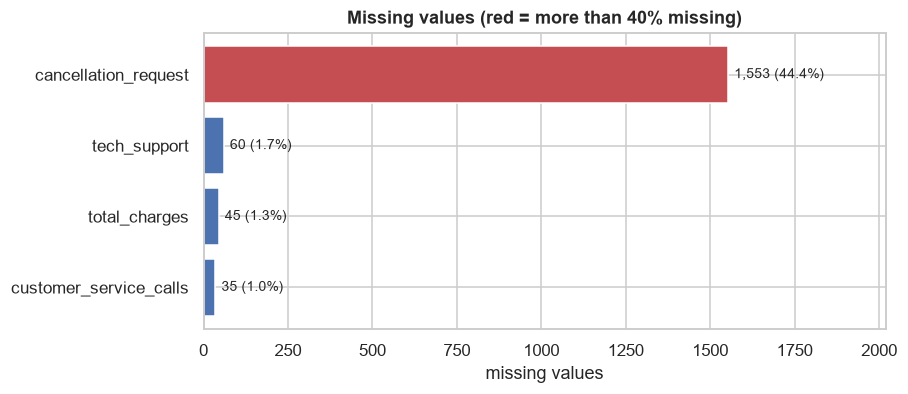

In [8]:
missing = missing_table(raw)

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(missing.index[::-1], missing["missing"][::-1],
               color=["#C44E52" if p > 40 else "#4C72B0" for p in missing["pct"][::-1]])
ax.bar_label(bars, labels=[f"{n:,} ({p:.1f}%)" for n, p in zip(missing["missing"][::-1], missing["pct"][::-1])],
             padding=4, fontsize=9)
ax.set_xlim(0, missing["missing"].max() * 1.3)
ax.set_xlabel("missing values")
ax.set_title("Missing values (red = more than 40% missing)")
plt.show()

**Trap — `dropna()` deletes your dataset.** Check what a naive `dropna()` would do before using it:

```python
raw.dropna().shape     # (1866, 23): 1,634 rows (46.7%) disappear!
```

**The four missing-value strategies** (pick one per column, and write down why):

| Strategy | When it is right | Example here |
|---|---|---|
| Drop the column | almost always missing and not useful | `cancellation_request` (but it is leakage anyway) |
| Drop the rows | very few rows, missing completely at random | not needed here |
| Keep as a category | missing is a meaningful state | `tech_support` → `"Unknown"` |
| Impute a value | small random gap, and you flag it | `customer_service_calls` → median + flag |

**Why this matters.** Missingness can be informative. In this dataset, whether
`cancellation_request` is missing tells you the answer (Insight 5). Imputing it with `"No"` would
destroy that information — and the column leaks anyway.

## 4. Duplicates and keys

Duplicate rows double-count customers and can leak the same example into train and test.

In [9]:
print("duplicate rows   :", int(raw.duplicated().sum()))
print("duplicate ids    :", int(raw["customer_id"].duplicated().sum()))
print("id is unique     :", raw["customer_id"].is_unique)

duplicate rows   : 0
duplicate ids    : 0
id is unique     : True


Three checks, three different bugs:

* `duplicated()` → the same customer appears twice.
* `customer_id.duplicated()` → the same ID is reused (data-export bug).
* `is_unique` → a one-line assertion you can keep in a test suite.

## 5. The target: balance and base rate

The **base rate** is the share of positives. It sets the floor every model must beat and decides
which metric is honest.

In [10]:
counts = raw["churn"].value_counts().sort_index()
rates = raw["churn"].value_counts(normalize=True).sort_index()
summary = pd.DataFrame({"customers": counts, "share": rates.round(3)})
summary.index = ["stayed (0)", "churned (1)"]
summary

,customers,share
stayed (0),1553,0.444
churned (1),1947,0.556


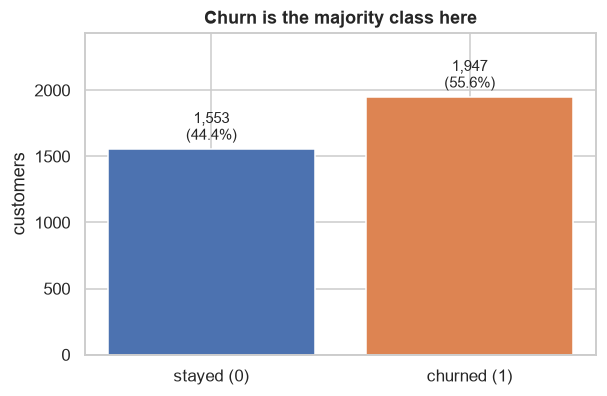

Dummy model accuracy (always predict churn): 0.556


In [11]:
fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(summary.index, summary["customers"], color=["#4C72B0", "#DD8452"])
for bar, n, p in zip(bars, summary["customers"], summary["share"]):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 40, f"{n:,}\n({p:.1%})",
            ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, counts.max() * 1.25)
ax.set_ylabel("customers")
ax.set_title("Churn is the majority class here")
plt.show()

print(f"Dummy model accuracy (always predict churn): {rates.max():.3f}")

**The accuracy trap.** If 55.6% of customers churn, "everyone churns" is 55.6% accurate and
completely useless (it never identifies a stayer). This is why churn projects report **recall,
precision, PR-AUC and cost**, not accuracy.

**Why this matters.** The base rate is also a realism check: the real Telco dataset churns at about
26.5%, so this synthetic file exaggerates churn. An insight about *this* file is not automatically
an insight about the business.

## 6. Distributions of numeric columns

`describe()` summarises each numeric column: count, mean, std, min, quartiles, max.

In [12]:
num_cols = ["tenure_months", "monthly_charges", "total_charges",
            "customer_service_calls", "satisfaction_score"]
raw[num_cols].describe().round(2)

,tenure_months,monthly_charges,total_charges,customer_service_calls,satisfaction_score
count,3500.00,3500.00,3455.00,3465.0,3500.00
mean,23.12,68.93,1583.23,2.5,2.75
std,20.39,22.21,1558.53,1.9,1.40
min,1.00,18.25,18.00,0.0,1.00
25%,7.00,56.77,404.14,1.0,1.00
50%,17.00,73.55,1062.18,2.0,3.00
75%,33.25,85.62,2259.63,4.0,4.00
max,72.00,110.09,7934.50,11.0,5.00


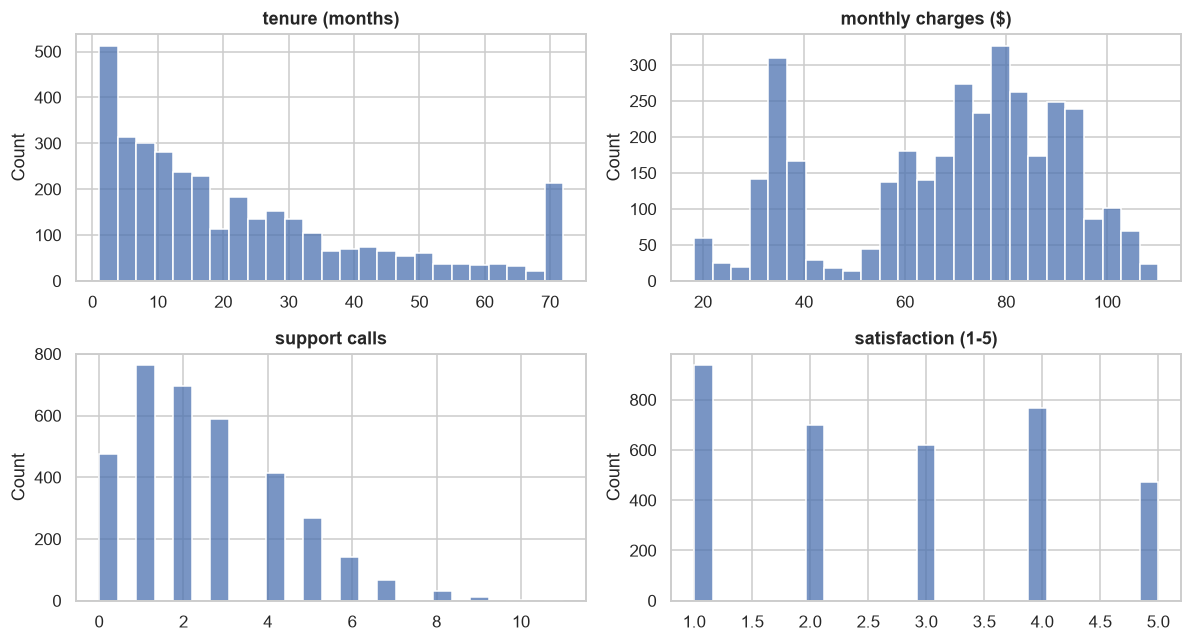

Skewness (0 = symmetric, >1 = strongly right-skewed):
tenure_months             1.03
monthly_charges          -0.51
total_charges             1.45
customer_service_calls    0.80
satisfaction_score        0.15


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
plot_cols = ["tenure_months", "monthly_charges", "customer_service_calls", "satisfaction_score"]
titles = ["tenure (months)", "monthly charges ($)", "support calls", "satisfaction (1-5)"]
for ax, col, title in zip(axes.flat, plot_cols, titles):
    sns.histplot(raw[col].dropna(), bins=25, ax=ax, color="#4C72B0")
    ax.set_title(title)
    ax.set_xlabel("")
fig.tight_layout()
plt.show()

print("Skewness (0 = symmetric, >1 = strongly right-skewed):")
print(raw[num_cols].skew().round(2).to_string())

**How to read skew.** Tenure's mean is larger than its median because a minority of customers stay
for years while most leave early — a long right tail. For skewed data:

* report the **median** ("half of customers stay less than 17 months"), not just the mean;
* be careful with tests that assume normality (Day 5 covered this);
* a log scale can make a skewed histogram readable, but do not transform for EDA unless it helps.

## 7. Target vs features — the core of EDA

This is where you stop describing columns and start answering questions like *"do month-to-month
customers leave more often?"* The pattern is always the same: **group by a feature, aggregate the
target**.

`groupby(...).agg()` with named aggregations is the cleanest way to write it:

In [14]:
by_contract = (
    raw.groupby("contract")["churn"]
    .agg(customers="size", churn_rate="mean")
    .sort_values("churn_rate", ascending=False)
)
by_contract["churn_pct"] = (by_contract["churn_rate"] * 100).round(1)
by_contract

,customers,churn_rate,churn_pct
contract,,,
Month-to-month,1937,0.706247,70.6
One year,764,0.489529,49.0
Two year,799,0.256571,25.7


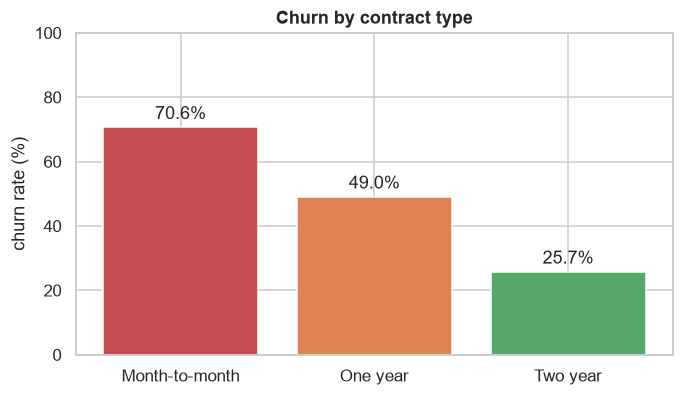

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(by_contract.index, by_contract["churn_pct"], color=["#C44E52", "#DD8452", "#55A868"])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 100)
ax.set_ylabel("churn rate (%)")
ax.set_title("Churn by contract type")
plt.show()

**Two categories at once: `crosstab`.** `pd.crosstab` counts combinations; adding `values=` and
`aggfunc="mean"` turns it into a rate table.

In [16]:
combo = pd.crosstab(
    raw["contract"],
    raw["internet_service"],
    values=raw["churn"],
    aggfunc="mean",
).round(3)
combo.index.name = "contract / internet"
combo

internet_service,DSL,Fiber optic,No
contract / internet,,,
Month-to-month,0.641,0.824,0.566
One year,0.392,0.639,0.349
Two year,0.188,0.372,0.149


**Turning a number into a segment: `pd.cut`.** Binning a continuous column makes it readable for
non-technical stakeholders (and reveals non-linear patterns that a correlation hides).

In [17]:
raw["tenure_band"] = pd.cut(
    raw["tenure_months"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=["1-12", "13-24", "25-36", "37-48", "49-60", "61-72"],
)

by_tenure = (
    raw.groupby("tenure_band", observed=False)["churn"]
    .agg(customers="size", churn_rate="mean")
)
by_tenure["churn_pct"] = (by_tenure["churn_rate"] * 100).round(1)
by_tenure

,customers,churn_rate,churn_pct
tenure_band,,,
1-12,1409,0.697658,69.8
13-24,809,0.615575,61.6
25-36,518,0.465251,46.5
37-48,270,0.377778,37.8
49-60,190,0.357895,35.8
61-72,304,0.180921,18.1


**How to read it.** Churn falls from 69.8% in the first year to 18.1% after five years. The pattern
is monotonic, which makes it credible. If one bin jumped around randomly, you would suspect noise.

**Why this matters.** Grouping is how you find actionable segments. "Tenure correlates with churn"
is a statistic; "customers in months 1–12 churn at 69.8%" is a business sentence someone can act on.

## 8. Correlations

Correlation measures whether two numbers move together, between −1 and +1. For a quick ranking of
numeric features against the target:

```python
raw[num_cols + ["churn"]].corr()["churn"].sort_values()
```

In [18]:
corr = raw[num_cols + ["churn"]].corr(numeric_only=True)
corr["churn"].sort_values(ascending=False).round(3)

churn                     1.000
customer_service_calls    0.567
monthly_charges           0.192
total_charges            -0.238
tenure_months            -0.333
satisfaction_score       -0.783
Name: churn, dtype: float64

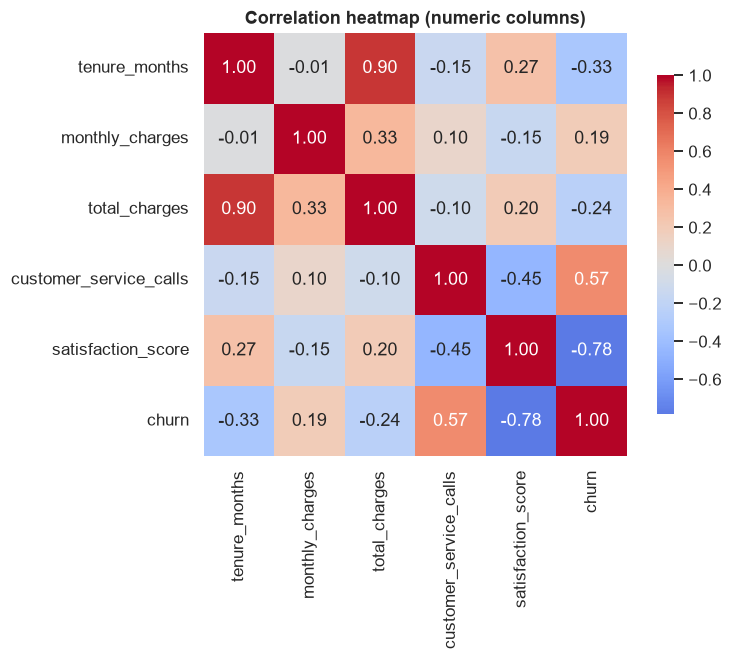

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.set_title("Correlation heatmap (numeric columns)")
plt.show()

**Three warnings about correlation:**

1. **It only sees linear, numeric relationships.** Contract type is the strongest driver, but it is
   text — it never appears in this matrix. Use groupby for categories.
2. **Correlation is not causation.** Month-to-month contracts correlate with churn, but the causal
   story (commitment reduces the opportunity to leave) needs an experiment to confirm.
3. **Derived columns inflate it.** `total_charges ≈ monthly_charges × tenure`, so it correlates with
   tenure at 0.90. Feeding both into a linear model creates collinearity.

Pearson (default) measures a straight-line relationship; Spearman measures a monotonic one and is
more robust to outliers and skew:

```python
raw[["tenure_months", "churn"]].corr(method="spearman")
```

## 9. Leakage — the check everyone forgets

**Leakage** = a feature that contains information about the target that would not be available at
prediction time. The classic symptoms are suspiciously perfect scores and a column that exists only
*after* the outcome.

The test: for each suspicious column, cross-tabulate it against the target. If a value maps to 100%
churn, it is not a feature — it is the label in disguise.

In [20]:
for col in ["cancellation_request", "churn_risk_post_exit_code", "last_interaction_status",
            "satisfaction_score"]:
    table = pd.crosstab(raw[col].fillna("(missing)"), raw["churn"], normalize="columns").round(3)
    print(f"--- {col} ---")
    print(table.to_string())
    print()

--- cancellation_request ---
churn                   0    1
cancellation_request          
(missing)             1.0  0.0
Recorded              0.0  1.0

--- churn_risk_post_exit_code ---
churn                        0    1
churn_risk_post_exit_code          
100                        1.0  0.0
999                        0.0  1.0

--- last_interaction_status ---
churn                         0      1
last_interaction_status               
Account Closed            0.000  0.690
Active Support            0.320  0.000
Bill Query                0.304  0.000
Final Invoice Dispatched  0.000  0.097
Plan Upgrade              0.174  0.000
Retention Declined        0.000  0.213
Routine Inquiry           0.202  0.000

--- satisfaction_score ---
churn                   0      1
satisfaction_score              
1                   0.000  0.481
2                   0.059  0.313
3                   0.202  0.157
4                   0.434  0.049
5                   0.305  0.000



**Reading the output:**

* `cancellation_request`: `"Recorded"` → 100% churn; missing → 100% stayed. It is recorded *when the
  customer cancels*.
* `churn_risk_post_exit_code`: `999` for every churner, `100` for every stayer — the target encoded
  as a number.
* `last_interaction_status`: "Account Closed" / "Retention Declined" / "Final Invoice Dispatched"
  are all post-exit events and all 100% churn.
* `satisfaction_score`: 100% churn at score 1, 0% at score 5 — a survey taken **at exit**.

**The rule.** If a model using a column gets ~100% accuracy on a problem this noisy, the column is
leakage. Remove it, then re-check. A useful habit is to ask of every column:
*"Would I know this value at the moment I need to make the prediction?"*

## 10. How to write an insight

An insight is not "contract matters". It has four parts:

| Part | Question | Example |
|---|---|---|
| Observation | What did I see? | Month-to-month churn is 70.6% vs 25.7% for two-year. |
| Evidence | How strong is it? | 1,937 vs 799 customers; the gap is 45 points. |
| Meaning | Why does it matter? | Commitment is the largest controllable risk factor. |
| Action | What should happen next? | Offer upgrades to month-to-month + fiber customers; A/B test it. |

**Weak:** "There is a relationship between contract and churn."
**Strong:** "Month-to-month customers churn at 70.6%, three times the two-year rate (25.7%);
the month-to-month + fiber segment is the largest high-risk pool (82.4%, n=860),
so it is the first candidate for a contract-upgrade experiment."

**Why this matters.** Interviewers remember the person who can turn a table into a decision. The
numbers are the easy part; the sentence is the skill.

## 11. Common EDA mistakes (checklist)

- [ ] Using accuracy on an imbalanced target.
- [ ] `dropna()` without checking how many rows disappear.
- [ ] Treating a unique ID as a feature.
- [ ] Forgetting to check duplicates.
- [ ] Reading a correlation without looking at the underlying groups.
- [ ] Keeping leakage columns because they improve the score.
- [ ] Writing insights without numbers, or numbers without an action.
- [ ] Not writing down *why* each cleaning decision was made.

## 12. Practice (try before opening the solutions)

### Exercise 1 — payment method
Which payment method has the highest churn rate, how many customers does it cover, and is the gap
big enough to act on?

<details>
<summary><b>Solution 1</b></summary>

```python
pay = (
    raw.groupby("payment_method")["churn"]
    .agg(customers="size", churn_rate="mean")
    .sort_values("churn_rate", ascending=False)
)
pay["churn_pct"] = (pay["churn_rate"] * 100).round(1)
pay
```

Electronic check churns at 63.6% (1,157 customers) versus ~50% for the automatic methods. The gap
(~14 points) is real but smaller than contract or tenure; it is a secondary segment, not the main
lever.

</details>

### Exercise 2 — senior citizens
Do senior citizens churn more? Compute the rate and the group sizes, then decide whether the
difference is worth a dedicated campaign.

<details>
<summary><b>Solution 2</b></summary>

```python
raw.groupby("senior_citizen")["churn"].agg(customers="size", churn_rate="mean")
```

Seniors: 59.8% churn from 550 customers; non-seniors: 54.8% from 2,950. A 5-point gap on a small
group is weak evidence — not a priority compared with the 45-point contract gap.

</details>

### Exercise 3 — a mini risk scorecard
Combine `contract`, `tenure_band` and `calls_band`. List the five segments with the highest churn
rate that contain at least 100 customers. Which one would you target first, and why?

<details>
<summary><b>Solution 3</b></summary>

```python
raw["calls_band"] = pd.cut(raw["customer_service_calls"],
                           bins=[-1, 0, 2, 4, 6, 20],
                           labels=["0", "1-2", "3-4", "5-6", "7+"])
scorecard = (
    raw.groupby(["contract", "tenure_band", "calls_band"], observed=False)["churn"]
    .agg(customers="size", churn_rate="mean")
    .reset_index()
)
scorecard = scorecard[scorecard["customers"] >= 100].sort_values("churn_rate", ascending=False)
scorecard.head(5)
```

You will find month-to-month, short-tenure, high-call segments at 90%+ churn. Target them first
because they combine **high risk** with **enough customers to matter** — a 100% churn segment of
5 people is not a campaign.

</details>

## 13. Cheat sheet

| Task | pandas |
|---|---|
| Size | `df.shape`, `df.info()` |
| Look at rows | `df.head()`, `df.sample(5, random_state=42)` |
| Types / cardinality | `df.dtypes`, `df.nunique()` |
| Missing | `df.isna().sum()`, `df.isna().mean()` |
| Duplicates | `df.duplicated().sum()`, `df["id"].is_unique` |
| Target balance | `df["target"].value_counts(normalize=True)` |
| Summary stats | `df.describe()`, `df["col"].skew()` |
| Group rates | `df.groupby("col")["target"].agg(customers="size", rate="mean")` |
| Two-way rates | `pd.crosstab(df.a, df.b, values=df.t, aggfunc="mean")` |
| Bin a number | `pd.cut(df.x, bins=[...], labels=[...])` |
| Correlation | `df.corr(numeric_only=True)["target"]` |
| Save a figure | `fig.savefig("figures/name.png", bbox_inches="tight")` |

---

**Next:** open `eda_report.ipynb` for the polished, stakeholder-facing version of this analysis,
then take the 45-minute `blank_file_test.ipynb` to prove you can do it from a blank cell.